# 04 – Profit-aware retention targeting

**Inputs:** `data/processed/*.csv` (notebook 02), `model_output/models/*.joblib` and `val_predictions.csv` (notebook 03),
assumptions in [`src/config.yaml`](../src/config.yaml) (`business`, `sensitivity`, `segment_offers`, `targeting`).
**Logic:** [`src/value.py`](../src/value.py), [`src/targeting.py`](../src/targeting.py), [`src/scorecard.py`](../src/scorecard.py).
**Outputs:** `targeting_output/tables/` (policy results, sensitivity, segments, fairness, scorecard, customer targeting table),
`targeting_output/figures/t01–t09`, `targeting_output/targeting_report.xlsx`.

## The decision

| | |
|---|---|
| **Business decision** | Which customers receive a retention offer in this month's campaign, given a fixed budget |
| **Unit of analysis** | One customer (one account, `customerID`) |
| **Target** | `Churn = Yes`: the customer left within the last month (IBM data description) |
| **Evaluation period** | A one-month churn window. The data is a single snapshot with no dates, so there is no later period to test on |
| **Decision metric** | Net retention value under the stated assumptions: Σ over contacted customers of (churned × save_rate × V − offer_cost) |
| **Decision time** | Start of the month, before churn happens. All predictors are account attributes known at that time (see the leakage note in section 0) |

| Done here | How |
|---|---|
| 1. Value proxy | `V = MonthlyCharges × margin × annuity(horizon)` |
| 2. EV rule and break-even | `EV = p × save_rate × V − offer_cost`, contact while EV > 0 and budget remains |
| 3. Main model | Net value of the EV policy on **val**, paired bootstrap |
| 4. Campaign size | Profit curve on **val** |
| 5. Final evaluation | **Test, once**: model metrics, EV vs simple rules with 95% CIs |
| 6. Sensitivity | save_rate × offer_cost grid, one-way tornado, budget curve |
| 7–8. Segments, fairness | Risk × value matrix, segment-specific offers, contact rates by customer group |
| 9. Explainability | LR points scorecard, SHAP for LightGBM |
| 10. Targeting table | Every customer: p, V, EV, rank, contact flag, reasons, suggested offer |

> **No causal claims.** The data has no retention campaign, so `save_rate` (the share of would-be churners an offer keeps)
> is an assumption, not an estimate, and this is not uplift modelling. Every money figure below reads
> "expected value *if* the offer saves `save_rate` of the churners it reaches".

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from IPython.display import display

from src import preprocessing as pp
from src import modeling as md
from src import value as vl
from src import targeting as tg
from src import scorecard as sc

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

config = pp.load_config()
biz, sens, tcfg = config["business"], config["sensitivity"], config["targeting"]
SEED = config["random_state"]

In [2]:
# Chart style matches notebooks 01–03
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, PURPLE, RED = "#2a78d6", "#eb6834", "#1baf7a", "#8a5cd1", "#d1453b"
MODEL_COLORS = {"lr": BLUE, "rf": ORANGE, "lgbm": AQUA}
POLICY_COLORS = {"ev": BLUE, "risk": ORANGE, "value": AQUA, "eda_rule": PURPLE, "random": MUTED, "oracle": AXIS}
LABELS, PL = md.MODEL_LABELS, tg.POLICY_LABELS
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 10,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
USD = FuncFormatter(lambda x, _: f"${x:,.0f}" if abs(x) < 1e4 else f"${x / 1e3:,.0f}k")
OUT_DIR = ROOT / "targeting_output"
FIG_DIR, TAB_DIR = OUT_DIR / "figures", OUT_DIR / "tables"
for d in (FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)


def money(x):
    return f"${x:,.0f}"


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 0. Data, splits and the stated assumptions

- **train** fits the models (notebook 03), **val** is used for every decision in this notebook (main model, campaign size),
  **test** is opened once in section 5 to report final numbers.
- **Leakage check at decision time.** The Kaggle file has only account attributes and `Churn`. The post-outcome columns
  of IBM's extended release (`Churn Reason`, `Churn Score`, `CLTV`) are not in it (asserted in notebook 03).
  `tenure` and `TotalCharges` are recorded at the snapshot, so for churners they include the final month. At the start of
  that month they would be one month lower, a small and uniform shift that does not reveal the outcome. This is noted as a limitation.

In [3]:
data = pp.load_processed(config)
train = data[data["split"] == "train"].reset_index(drop=True)
val = data[data["split"] == "val"].reset_index(drop=True)
test = data[data["split"] == "test"].reset_index(drop=True)
print({s: len(d) for s, d in [("train", train), ("val", val), ("test", test)]})

assumptions = pd.DataFrame([
    ("gross_margin", biz["gross_margin"], "Share of the monthly bill left after direct costs"),
    ("retention_horizon_months", biz["retention_horizon_months"], "Months a saved customer stays after the offer"),
    ("annual_discount_rate", biz["annual_discount_rate"], "Discount rate over the horizon"),
    ("offer_cost", biz["offer_cost"], "Cost per contacted customer (paid for churners and non-churners)"),
    ("save_rate", biz["save_rate"], "P(offer keeps a would-be churner). Assumed, not measured"),
    ("campaign_budget", biz["campaign_budget"], f"For the whole base of {biz['base_size']:,} customers"),
], columns=["parameter", "base case", "meaning"]).set_index("parameter")
display(assumptions)
print(f"Budget buys {tg.n_offers(biz['campaign_budget'], biz['offer_cost']):,} offers = "
      f"{tg.n_offers(biz['campaign_budget'], biz['offer_cost']) / biz['base_size']:.1%} of the base")

{'train': 4225, 'val': 1409, 'test': 1409}


,base case,meaning
parameter,,
gross_margin,0.50,Share of the monthly bill left after direct costs
retention_horizon_months,12.00,Months a saved customer stays after the offer
annual_discount_rate,0.10,Discount rate over the horizon
offer_cost,40.00,Cost per contacted customer (paid for churners...
save_rate,0.25,"P(offer keeps a would-be churner). Assumed, no..."
campaign_budget,40000.00,"For the whole base of 7,043 customers"


Budget buys 1,000 offers = 14.2% of the base


## 1. Customer value proxy

`V` is the margin a customer would still bring in over the retention horizon, i.e. what a prevented churn is worth:

$$V_i = \text{MonthlyCharges}_i \times \text{margin} \times \sum_{t=1}^{H} (1+r)^{-t}$$

Tenure enters as **past value** (`TotalCharges` ≈ tenure × MonthlyCharges), used to describe segments, not as a multiplier
inside V. Money already paid is sunk, and tenure's effect on future churn is already inside `p_churn`, so multiplying V by
tenure would count it twice (details in the `src/value.py` docstring). Longer expected lifetimes are covered by the horizon
assumption and its sensitivity range (section 6).

In [4]:
annuity = vl.annuity_factor(biz["retention_horizon_months"], biz["annual_discount_rate"])
v_all = vl.value_proxy(data, biz)
v_edges = vl.value_tier_edges(v_all, biz)
hv_threshold = float(np.quantile(v_all, biz["high_value_quantile"]))
print(f"Annuity factor for {biz['retention_horizon_months']} months at {biz['annual_discount_rate']:.0%}/yr: {annuity:.2f}")
print(f"V = MonthlyCharges × {biz['gross_margin']} × {annuity:.2f} = MonthlyCharges × {biz['gross_margin'] * annuity:.2f}")
print(f"High-value threshold (top {1 - biz['high_value_quantile']:.0%} of V): {money(hv_threshold)}")

base = vl.add_value_columns(data, biz, v_all)
value_profile = base.groupby("value_tier", sort=False).agg(
    n=("y", "size"), V_min=("value_proxy", "min"), V_mean=("value_proxy", "mean"), V_max=("value_proxy", "max"),
    past_value_mean=("past_value", "mean"), tenure_mean=("tenure", "mean"), churn_rate=("y", "mean"),
).reindex(biz["value_tiers"]["labels"])
value_profile["share_of_V_at_risk"] = (base.assign(vr=base["value_proxy"] * base["y"]).groupby("value_tier")["vr"].sum()
                                       / (base["value_proxy"] * base["y"]).sum())
value_profile.to_csv(TAB_DIR / "value_tiers.csv")
display(value_profile.style.format({"n": "{:,}", "V_min": "${:,.0f}", "V_mean": "${:,.0f}", "V_max": "${:,.0f}",
                                    "past_value_mean": "${:,.0f}", "tenure_mean": "{:.1f}", "churn_rate": "{:.1%}",
                                    "share_of_V_at_risk": "{:.1%}"}))

Annuity factor for 12 months at 10%/yr: 11.40
V = MonthlyCharges × 0.5 × 11.40 = MonthlyCharges × 5.70
High-value threshold (top 25% of V): $512


,n,V_min,V_mean,V_max,past_value_mean,tenure_mean,churn_rate,share_of_V_at_risk
value_tier,,,,,,,,
Low,"2,351",$104,$160,$287,$715,26.7,15.9%,9.1%
Medium,"2,345",$288,$394,$478,"$1,955",28.4,29.7%,35.7%
High,"2,347",$479,$555,$677,"$4,172",42.0,34.1%,55.1%


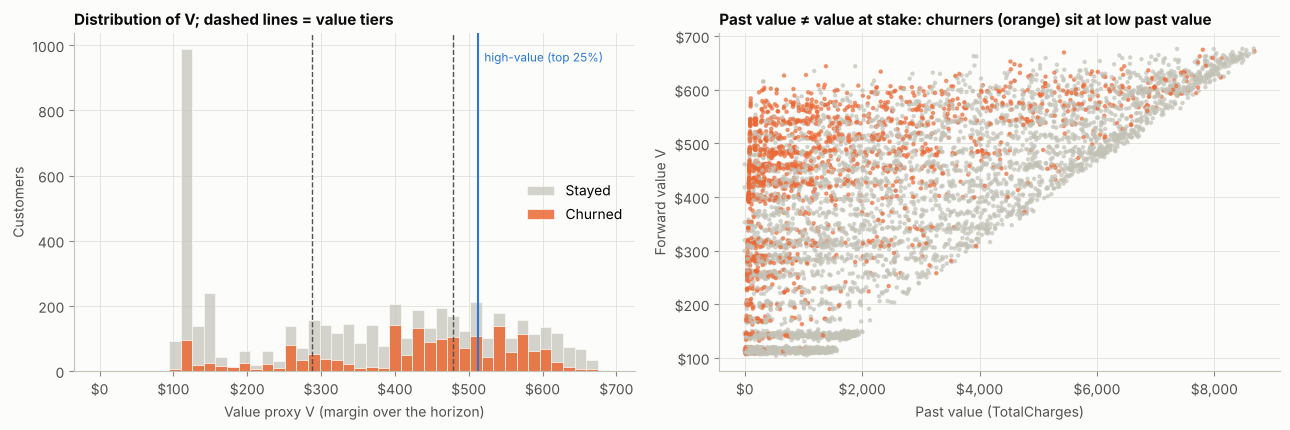

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))
bins = np.linspace(0, v_all.max() * 1.02, 45)
for yv, c, lab in [(0, AXIS, "Stayed"), (1, ORANGE, "Churned")]:
    ax1.hist(base.loc[base["y"] == yv, "value_proxy"], bins=bins, color=c, alpha=0.85 if yv else 0.7,
             edgecolor=SURFACE, linewidth=0.6, label=lab)
for e in v_edges[1:-1]:
    ax1.axvline(e, color=INK_2, ls="--", lw=1)
ax1.axvline(hv_threshold, color=BLUE, lw=1.5)
ax1.text(hv_threshold, ax1.get_ylim()[1] * 0.95, "  high-value (top 25%)", color=BLUE, fontsize=8.5, va="top")
ax1.xaxis.set_major_formatter(USD)
ax1.set_xlabel("Value proxy V (margin over the horizon)")
ax1.set_ylabel("Customers")
ax1.set_title("Distribution of V; dashed lines = value tiers", loc="left")
ax1.legend()
ax2.scatter(base["past_value"], base["value_proxy"], s=5, c=np.where(base["y"] == 1, ORANGE, AXIS), alpha=0.6)
ax2.xaxis.set_major_formatter(USD)
ax2.yaxis.set_major_formatter(USD)
ax2.set_xlabel("Past value (TotalCharges)")
ax2.set_ylabel("Forward value V")
ax2.set_title("Past value ≠ value at stake: churners (orange) sit at low past value", loc="left")
fig.tight_layout()
save(fig, "t01_value_proxy")

## 2. Expected-value rule and break-even

$$EV_i = p_i \cdot s \cdot V_i - c \qquad\text{contact } i \text{ if } EV_i > 0 \iff p_i > \frac{c}{s \cdot V_i}$$

- The break-even churn probability **differs per customer**: a high-value customer is worth an offer at a lower risk.
- With one offer for everyone, EV orders customers exactly like `p × MonthlyCharges` (expected margin at risk), **whatever**
  the values of save_rate, offer_cost, margin and horizon (checked below). The ranking is robust to the assumptions; the
  assumptions only set **how far down the list** an offer still pays and what the campaign is worth.

,EV order == p × MonthlyCharges order
"s=0.1, c=10, margin=0.3",True
"s=0.25, c=40, margin=0.5",True
"s=0.5, c=150, margin=0.7",True


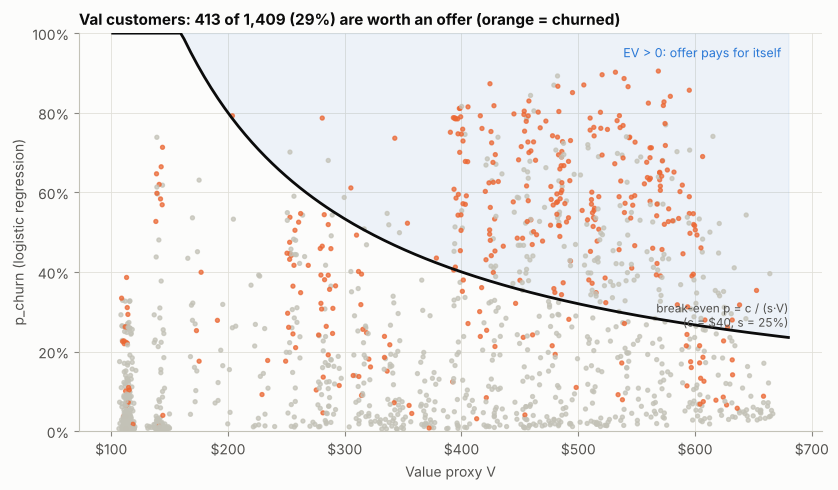

In [6]:
lr_model = joblib.load(ROOT / "model_output" / "models" / "lr.joblib")
p_val_lr = lr_model.predict_churn(val)
v_val = vl.value_proxy(val, biz)
ev_val = tg.expected_value(p_val_lr, v_val, biz["save_rate"], biz["offer_cost"])
rank_check = {}
for s, c, m in [(0.1, 10, 0.3), (0.25, 40, 0.5), (0.5, 150, 0.7)]:
    ev_alt = tg.expected_value(p_val_lr, vl.value_proxy(val, {**biz, "gross_margin": m}), s, c)
    rank_check[f"s={s}, c={c}, margin={m}"] = (np.argsort(-ev_alt, kind="stable") ==
                                                np.argsort(-(p_val_lr * val["MonthlyCharges"].to_numpy()), kind="stable")).all()
display(pd.Series(rank_check, name="EV order == p × MonthlyCharges order").to_frame())

fig, ax = plt.subplots(figsize=(8.5, 5))
vv = np.linspace(v_val.min() * 0.95, v_val.max() * 1.02, 200)
ax.plot(vv, np.clip(tg.breakeven_p(vv, biz["save_rate"], biz["offer_cost"]), 0, 1), color=INK, lw=2)
ax.fill_between(vv, np.clip(tg.breakeven_p(vv, biz["save_rate"], biz["offer_cost"]), 0, 1), 1, color=BLUE, alpha=0.07)
ax.scatter(v_val, p_val_lr, s=8, c=np.where(val["y"] == 1, ORANGE, AXIS), alpha=0.75)
ax.text(vv[-1], 0.97, "EV > 0: offer pays for itself  ", ha="right", va="top", color=BLUE, fontsize=9)
ax.text(vv[-1], tg.breakeven_p(vv[-1], biz["save_rate"], biz["offer_cost"]) + 0.02,
        f"break-even p = c / (s·V)\n(c = ${biz['offer_cost']}, s = {biz['save_rate']:.0%})", ha="right", va="bottom",
        color=INK_2, fontsize=8.5)
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(USD)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Value proxy V")
ax.set_ylabel("p_churn (logistic regression)")
ax.set_title(f"Val customers: {(ev_val > 0).sum():,} of {len(val):,} ({(ev_val > 0).mean():.0%}) are worth an offer "
             f"(orange = churned)", loc="left")
fig.tight_layout()
save(fig, "t02_breakeven")

## 3. Choosing the main model by business value (val)

Notebook 03 left the choice open: the three models were tied on technical metrics, and the rule was to compare **net value of
the EV policy at the reference budget on val**, keeping LR unless another model is better with a 95% CI that excludes 0.
Val probabilities are the cross-fitted ones saved by notebook 03 (calibration "none" was chosen, so they equal the raw ones).

In [7]:
val_pred = pd.read_csv(ROOT / "model_output" / "tables" / "val_predictions.csv").set_index(pp.ID_COL).loc[val[pp.ID_COL]]
assert (val_pred[pp.TARGET].to_numpy() == val[pp.TARGET].to_numpy()).all()
assert np.allclose(val_pred["p_lr"], p_val_lr)

k_val = tg.n_offers(tg.split_budget(biz, len(val)), biz["offer_cost"])
rng = np.random.default_rng(SEED)
boot_idx = rng.integers(0, len(val), size=(tcfg["n_bootstrap"], len(val)))
frames = {m: tg.Frame.from_df(val, val_pred[f"p_{m}"], v_val, val[pp.TARGET]) for m in md.MODELS}
draws = {m: np.array([tg.evaluate_policy("ev", frames[m].take(i), biz["save_rate"], biz["offer_cost"], k_val,
                                         hv_threshold)["net_value"] for i in boot_idx]) for m in md.MODELS}
rows = []
for m in md.MODELS:
    o = tg.evaluate_policy("ev", frames[m], biz["save_rate"], biz["offer_cost"], k_val, hv_threshold)
    diff = draws[m] - draws["lr"]
    rows.append({"model": LABELS[m], "net_value": o["net_value"], "ci_low": np.percentile(draws[m], 2.5),
                 "ci_high": np.percentile(draws[m], 97.5), "precision": o["precision"],
                 "diff_vs_lr": diff.mean(), "diff_ci_low": np.percentile(diff, 2.5), "diff_ci_high": np.percentile(diff, 97.5)})
model_choice = pd.DataFrame(rows).set_index("model")
model_choice.to_csv(TAB_DIR / "model_choice_val.csv")
display(model_choice.style.format({c: "${:,.0f}" for c in ["net_value", "ci_low", "ci_high", "diff_vs_lr", "diff_ci_low",
                                                          "diff_ci_high"]} | {"precision": "{:.1%}"}))

clearly_better = model_choice[(model_choice["diff_ci_low"] > 0)]
MAIN = "lr" if clearly_better.empty else {v: k for k, v in LABELS.items()}[clearly_better["diff_vs_lr"].idxmax()]
assert MAIN == tcfg["main_model"], "config.yaml → targeting.main_model disagrees with this section; update the config"
print(f"Budget on val: {money(tg.split_budget(biz, len(val)))} → {k_val} offers. Main model: {LABELS[MAIN]}")

,net_value,ci_low,ci_high,precision,diff_vs_lr,diff_ci_low,diff_ci_high
model,,,,,,,
Logistic regression,"$9,968","$8,457","$11,769",70.5%,$0,$0,$0
Random forest,"$9,686","$7,879","$11,212",70.0%,$-485,"$-1,353",$364
LightGBM,"$9,873","$7,992","$11,502",70.0%,$-316,"$-1,196",$500


Budget on val: $8,002 → 200 offers. Main model: Logistic regression


**Result.** All three models produce almost the same campaign value on val, and no difference from LR has a CI that excludes 0.
Following the rule fixed before looking at test, **logistic regression is the main model**: it is as good as the alternatives,
its probabilities are well calibrated, and it can be written as a points scorecard (section 9).

## 4. Policies and campaign size on val

Policies compared at the same budget (same number of offers):

| Policy | Contacts first | Uses |
|---|---|---|
| **Expected value** | highest `p × s × V − c`, only if > 0 | model + value |
| Highest churn risk | highest `p` | model only (the "simple rule" in the brief) |
| Highest value only | highest `V` | no model |
| EDA rule | Month-to-month × Fiber, newest first | EDA segment, no model |
| Random | — | expected value of a random pick, as a floor |
| Perfect foresight | actual churners with the highest V | **not achievable**, ceiling for reference |

In [8]:
f_val = frames[MAIN]
val_policies = tg.compare_policies(f_val, biz, hv_threshold)
val_policies.to_csv(TAB_DIR / "policies_val.csv")
cols = ["contacted", "spend", "churners_contacted", "net_value", "expected_net", "roi", "precision", "recall",
        "hv_churner_coverage"]
FMT = {"contacted": "{:,.0f}", "spend": "${:,.0f}", "churners_contacted": "{:,.0f}", "net_value": "${:,.0f}",
       "expected_net": "${:,.0f}", "roi": "{:.0%}", "precision": "{:.1%}", "recall": "{:.1%}",
       "hv_churner_coverage": "{:.1%}", "saved_value": "${:,.0f}"}
display(val_policies[cols].astype(float).style.format(FMT))

curves_val = {pol: tg.profit_curve(tg.priority(pol, f_val, biz["save_rate"], biz["offer_cost"])[0], f_val,
                                   biz["save_rate"], biz["offer_cost"]) for pol in ["ev", "risk", "value"]}
exp_curve_val = tg.profit_curve(tg.priority("ev", f_val, biz["save_rate"], biz["offer_cost"])[0], f_val,
                                biz["save_rate"], biz["offer_cost"], expected=True)
k_opt_val = int(np.argmax(exp_curve_val))
k_opt_share = k_opt_val / len(val)
rec_offers = int(round(k_opt_share * biz["base_size"]))
rec_budget = rec_offers * biz["offer_cost"]
print(f"Expected-value optimum on val: contact {k_opt_val} of {len(val)} ({k_opt_share:.1%}) = every customer with EV > 0")
print(f"Scaled to the base: about {rec_offers:,} offers, budget ≈ {money(rec_budget)} "
      f"(the reference budget {money(biz['campaign_budget'])} buys {tg.n_offers(biz['campaign_budget'], biz['offer_cost']):,})")
print(f"Realized net on val at the EV optimum: {money(curves_val['ev'][k_opt_val])} vs {money(curves_val['ev'][k_val])} "
      f"at the reference budget")

,contacted,spend,churners_contacted,net_value,expected_net,roi,precision,recall,hv_churner_coverage
policy,,,,,,,,,
Expected value (model),200,"$8,000",141,"$9,968","$9,381",125%,70.5%,37.7%,59.5%
Highest churn risk (model),200,"$8,000",145,"$9,057","$8,334",113%,72.5%,38.8%,42.9%
Highest value only,200,"$8,000",62,"$1,269",$46,16%,31.0%,16.6%,49.2%
"EDA rule: M2M + Fiber, newest first",200,"$8,000",140,"$8,716","$7,813",109%,70.0%,37.4%,33.3%
Random,200,"$8,000",53,"$-2,264","$-2,395",-28%,26.5%,14.2%,14.2%
Perfect foresight (upper bound),200,"$8,000",200,"$18,817","$6,121",235%,100.0%,53.5%,100.0%


Expected-value optimum on val: contact 413 of 1409 (29.3%) = every customer with EV > 0
Scaled to the base: about 2,064 offers, budget ≈ $82,560 (the reference budget $40,000 buys 1,000)
Realized net on val at the EV optimum: $12,699 vs $9,968 at the reference budget


On val the EV policy earns the most of the achievable policies at the reference budget, and the budget is **binding**: there are
more customers with EV > 0 than the reference budget can reach. The profit curve flattens near the EV > 0 cut-off, so the
extra offers beyond the reference budget add value but at a falling rate (section 6 shows how much under different assumptions).

## 5. Final evaluation on test (used once)

Everything above (main model, policies, campaign size, assumptions) was fixed on train/val. Test is scored now, once.

In [9]:
models = {m: joblib.load(ROOT / "model_output" / "models" / f"{m}.joblib") for m in md.MODELS}
p_test = {m: models[m].predict_churn(test) for m in md.MODELS}
y_test = test[pp.TARGET].to_numpy()
test_metrics = pd.DataFrame({LABELS[m]: md.evaluate(p_test[m], y_test, config["calibration"]["n_bins"])
                             for m in md.MODELS}).T
val_metrics = pd.read_csv(ROOT / "model_output" / "tables" / "val_metrics.csv", index_col=0)
test_metrics.to_csv(TAB_DIR / "test_model_metrics.csv")
display(pd.concat({"val": val_metrics, "test": test_metrics}, axis=1)
        .swaplevel(axis=1)[["roc_auc", "pr_auc", "log_loss", "brier", "ece", "calib_slope"]]
        .style.format("{:.3f}"))

boot_test = md.bootstrap_compare({LABELS[m]: p_test[m] for m in md.MODELS}, y_test, ref=LABELS["lr"],
                                 n_boot=config["threshold_analysis"]["n_bootstrap"], seed=SEED)
boot_test.to_csv(TAB_DIR / "test_model_bootstrap.csv", index=False)
display(boot_test.set_index(["metric", "model"])[["estimate", "ci_low", "ci_high", "diff_ci_low", "diff_ci_high"]]
        .style.format("{:.3f}"))

,,estimate,ci_low,ci_high,diff_ci_low,diff_ci_high
metric,model,,,,,
roc_auc,Logistic regression,0.848,0.828,0.871,0.000,0.000
pr_auc,Logistic regression,0.666,0.619,0.717,0.000,0.000
log_loss,Logistic regression,0.413,0.383,0.440,0.000,0.000
brier,Logistic regression,0.135,0.124,0.144,0.000,0.000
roc_auc,Random forest,0.843,0.823,0.866,-0.010,0.002
pr_auc,Random forest,0.652,0.604,0.705,-0.030,0.002
log_loss,Random forest,0.417,0.390,0.441,-0.003,0.012
brier,Random forest,0.137,0.126,0.146,-0.001,0.005
roc_auc,LightGBM,0.846,0.826,0.869,-0.007,0.003


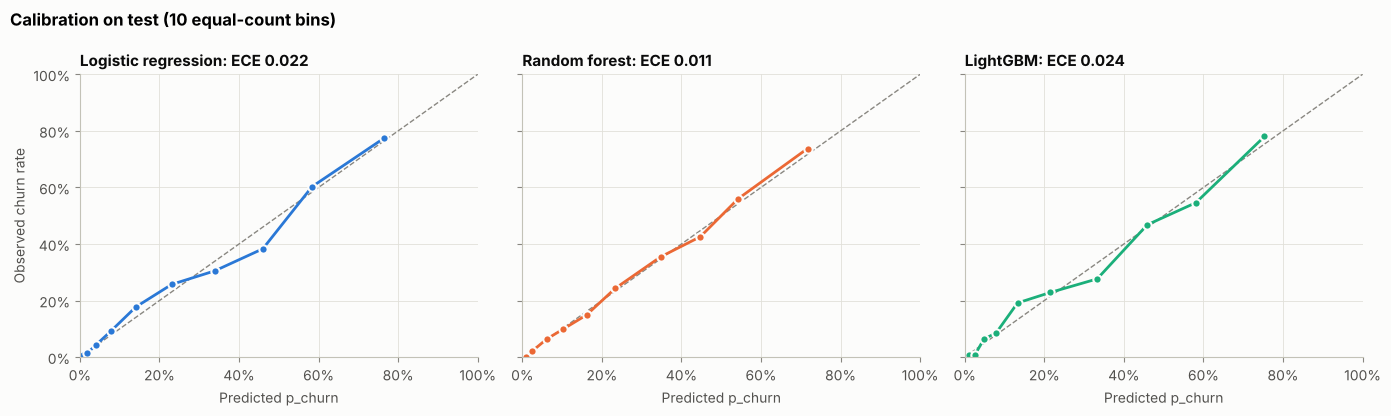

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, m in zip(axes, md.MODELS):
    t = md.reliability_table(p_test[m], y_test, config["calibration"]["n_bins"])
    ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
    ax.plot(t["mean_p"], t["churn_rate"], color=MODEL_COLORS[m], lw=2, marker="o", ms=6,
            markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax.set_title(f"{LABELS[m]}: ECE {test_metrics.loc[LABELS[m], 'ece']:.3f}", loc="left")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("Predicted p_churn")
axes[0].set_ylabel("Observed churn rate")
fig.suptitle("Calibration on test (10 equal-count bins)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "t03_test_calibration")

In [11]:
v_test = vl.value_proxy(test, biz)
f_test = tg.Frame.from_df(test, p_test[MAIN], v_test, y_test)
k_test = tg.n_offers(tg.split_budget(biz, len(test)), biz["offer_cost"])
test_policies = tg.compare_policies(f_test, biz, hv_threshold)
test_boot = tg.bootstrap_policies(f_test, biz, hv_threshold, ref="risk", n_boot=tcfg["n_bootstrap"], seed=SEED)
test_policies = test_policies.join(test_boot)
test_policies.to_csv(TAB_DIR / "policies_test.csv")
print(f"Test: {len(test):,} customers, budget {money(tg.split_budget(biz, len(test)))} → {k_test} offers")
display(test_policies[cols].astype(float).style.format(FMT))
display(test_policies[["net_value_lo", "net_value_hi", "net_diff_vs_ref", "net_diff_lo", "net_diff_hi", "p_better_than_ref"]]
        .astype(float).style.format("${:,.0f}").format("{:.0%}", subset=["p_better_than_ref"]))

Test: 1,409 customers, budget $8,002 → 200 offers


,contacted,spend,churners_contacted,net_value,expected_net,roi,precision,recall,hv_churner_coverage
policy,,,,,,,,,
Expected value (model),200,"$8,000",137,"$8,869","$9,409",111%,68.5%,36.6%,53.4%
Highest churn risk (model),200,"$8,000",145,"$8,183","$8,405",102%,72.5%,38.8%,35.0%
Highest value only,200,"$8,000",58,$605,$483,8%,29.0%,15.5%,56.3%
"EDA rule: M2M + Fiber, newest first",200,"$8,000",134,"$7,707","$8,146",96%,67.0%,35.8%,30.1%
Random,200,"$8,000",53,"$-2,495","$-2,389",-31%,26.5%,14.2%,14.2%
Perfect foresight (upper bound),200,"$8,000",200,"$17,970","$6,013",225%,100.0%,53.5%,100.0%


,net_value_lo,net_value_hi,net_diff_vs_ref,net_diff_lo,net_diff_hi,p_better_than_ref
policy,,,,,,
Expected value (model),"$7,049","$10,492",$784,$-262,"$1,942",92%
Highest churn risk (model),"$6,508","$9,467",$0,$0,$0,0%
Highest value only,"$-1,461","$2,397","$-7,491","$-9,562","$-5,333",0%
"EDA rule: M2M + Fiber, newest first","$6,248","$9,321",$-236,"$-1,437",$995,35%
Random,"$-3,034","$-1,998","$-10,464","$-11,875","$-9,172",0%
Perfect foresight (upper bound),"$17,238","$18,657","$9,976","$8,555","$11,392",100%


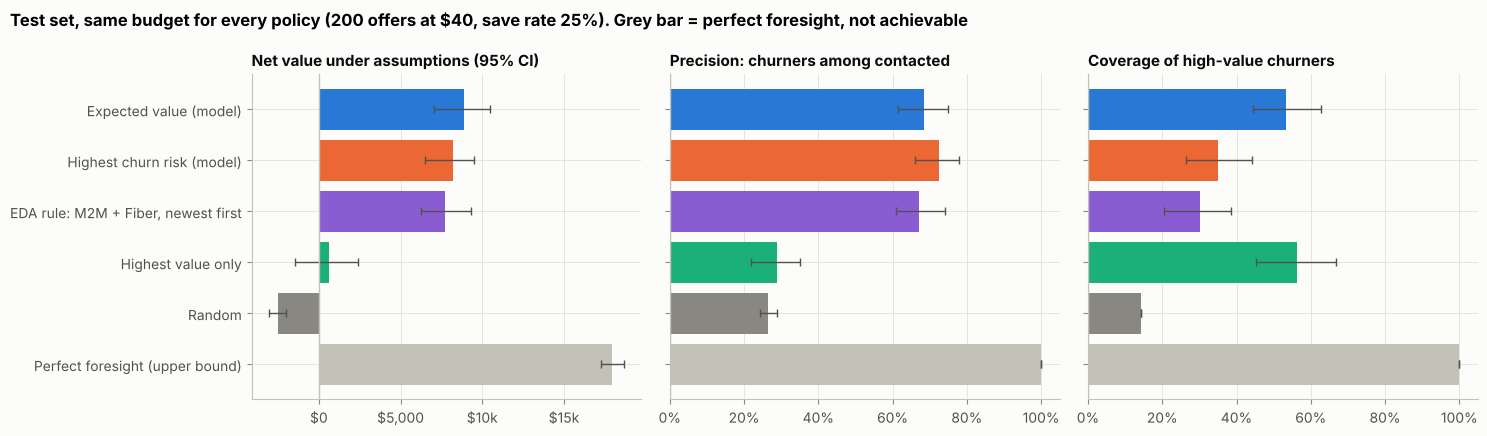

In [12]:
order = ["ev", "risk", "eda_rule", "value", "random", "oracle"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, (metric, title, fmt) in zip(axes, [("net_value", "Net value under assumptions (95% CI)", USD),
                                           ("precision", "Precision: churners among contacted", PercentFormatter(1, 0)),
                                           ("hv_churner_coverage", "Coverage of high-value churners",
                                            PercentFormatter(1, 0))]):
    vals = test_policies.loc[[PL[p] for p in order], metric].astype(float)
    ax.barh(range(len(order)), vals, color=[POLICY_COLORS[p] for p in order])
    if metric in ("net_value", "precision", "hv_churner_coverage"):
        lo = test_policies.loc[[PL[p] for p in order], f"{metric}_lo"].astype(float)
        hi = test_policies.loc[[PL[p] for p in order], f"{metric}_hi"].astype(float)
        ax.errorbar(vals, range(len(order)), xerr=[vals - lo, hi - vals], fmt="none", ecolor=INK_2, capsize=3, lw=1)
    ax.set_yticks(range(len(order)), [PL[p] for p in order] if ax is axes[0] else [""] * len(order))
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(fmt)
    ax.axvline(0, color=AXIS, lw=1)
    ax.set_title(title, loc="left")
fig.suptitle(f"Test set, same budget for every policy ({k_test} offers at ${biz['offer_cost']}, save rate "
             f"{biz['save_rate']:.0%}). Grey bar = perfect foresight, not achievable", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "t04_policy_comparison")

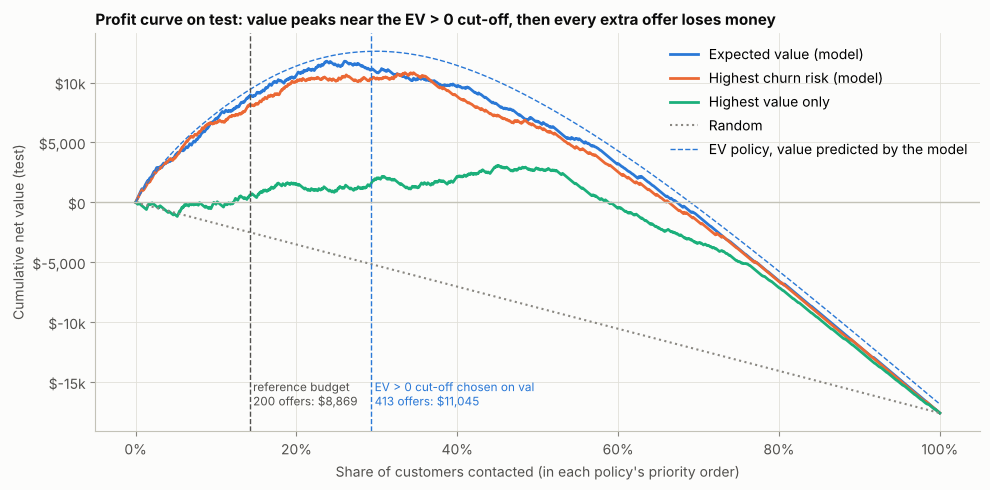

Test, EV cut-off from val (413 offers): net $11,045; best possible point on the realized EV curve: 335 offers, $11,785


In [13]:
curves_test = {pol: tg.profit_curve(tg.priority(pol, f_test, biz["save_rate"], biz["offer_cost"])[0], f_test,
                                    biz["save_rate"], biz["offer_cost"]) for pol in ["ev", "risk", "value"]}
rand_curve = np.arange(len(test) + 1) * (biz["save_rate"] * (y_test * v_test).mean() - biz["offer_cost"])
exp_curve_test = tg.profit_curve(tg.priority("ev", f_test, biz["save_rate"], biz["offer_cost"])[0], f_test,
                                 biz["save_rate"], biz["offer_cost"], expected=True)
k_rec_test = int(round(k_opt_share * len(test)))
share = np.arange(len(test) + 1) / len(test)

fig, ax = plt.subplots(figsize=(10, 5))
for pol, curve in curves_test.items():
    ax.plot(share, curve, color=POLICY_COLORS[pol], lw=2, label=PL[pol])
ax.plot(share, rand_curve, color=MUTED, lw=1.5, ls=":", label=PL["random"])
ax.plot(share, exp_curve_test, color=BLUE, lw=1, ls="--", label="EV policy, value predicted by the model")
for k, lab, c in [(k_test, "reference budget", INK_2), (k_rec_test, "EV > 0 cut-off chosen on val", BLUE)]:
    ax.axvline(k / len(test), color=c, lw=1, ls="--")
    ax.text(k / len(test), ax.get_ylim()[0] * 0.9, f" {lab}\n {k} offers: {money(curves_test['ev'][k])}", color=c,
            fontsize=8.5, va="bottom")
ax.axhline(0, color=AXIS, lw=1)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(USD)
ax.set_xlabel("Share of customers contacted (in each policy's priority order)")
ax.set_ylabel("Cumulative net value (test)")
ax.set_title("Profit curve on test: value peaks near the EV > 0 cut-off, then every extra offer loses money", loc="left")
ax.legend(loc="upper right")
fig.tight_layout()
save(fig, "t05_profit_curve")

profit_curve_table = pd.DataFrame({"share_contacted": share, "k": np.arange(len(test) + 1),
                                   **{f"net_{pol}": c for pol, c in curves_test.items()}, "net_random": rand_curve,
                                   "expected_net_ev": exp_curve_test})
profit_curve_table.to_csv(TAB_DIR / "profit_curve_test.csv", index=False)
print(f"Test, EV cut-off from val ({k_rec_test} offers): net {money(curves_test['ev'][k_rec_test])}; "
      f"best possible point on the realized EV curve: {np.argmax(curves_test['ev'])} offers, "
      f"{money(curves_test['ev'].max())}")

## 6. Sensitivity analysis (test)

Save rate and offer cost are the two least certain inputs. The grid keeps the **budget in dollars fixed**, so a cheaper offer
buys more contacts; the EV policy still contacts only customers with EV > 0, so it may leave budget unspent when offers are
expensive or rarely work.

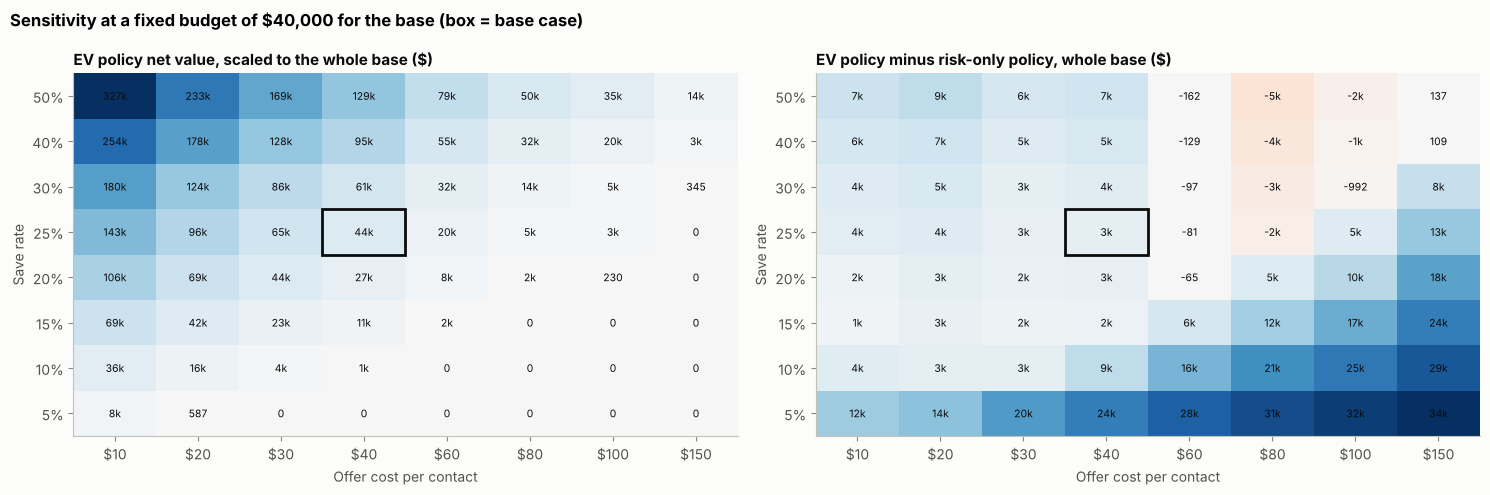

Cells where the campaign does not pay (EV policy contacts nobody or loses money): 15 of 64
EV beats risk-only in 81% of cells; loses in 12 cells


In [14]:
grid = tg.sensitivity_grid(f_test, biz, hv_threshold, sens["save_rate"], sens["offer_cost"])
grid.to_csv(TAB_DIR / "sensitivity_grid_test.csv", index=False)
scale_up = biz["base_size"] / len(test)


def heat(ax, table, value, title, cmap, center=None, fmt="{:,.0f}", scale=1.0):
    piv = table.pivot(index="save_rate", columns="offer_cost", values=value) * scale
    lim = np.nanmax(np.abs(piv.to_numpy()))
    im = ax.imshow(piv.to_numpy(), cmap=cmap, aspect="auto", origin="lower",
                   vmin=-lim if center == 0 else None, vmax=lim if center == 0 else None)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            x = piv.iloc[i, j]
            ax.text(j, i, fmt.format(x / 1e3) + "k" if abs(x) >= 1e3 else fmt.format(x), ha="center", va="center",
                    fontsize=7.5, color=INK)
    ax.set_xticks(range(piv.shape[1]), [f"${c:g}" for c in piv.columns])
    ax.set_yticks(range(piv.shape[0]), [f"{s:.0%}" for s in piv.index])
    ax.set_xlabel("Offer cost per contact")
    ax.set_ylabel("Save rate")
    ax.grid(False)
    ax.set_title(title, loc="left")
    i0, j0 = list(piv.index).index(biz["save_rate"]), list(piv.columns).index(biz["offer_cost"])
    ax.add_patch(plt.Rectangle((j0 - 0.5, i0 - 0.5), 1, 1, fill=False, ec=INK, lw=2))


fig, axes = plt.subplots(1, 2, figsize=(15, 5))
heat(axes[0], grid, "ev_net", "EV policy net value, scaled to the whole base ($)", "RdBu", center=0, scale=scale_up)
heat(axes[1], grid, "ev_minus_risk", "EV policy minus risk-only policy, whole base ($)", "RdBu", center=0, scale=scale_up)
fig.suptitle(f"Sensitivity at a fixed budget of {money(biz['campaign_budget'])} for the base (box = base case)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "t06_sensitivity_grid")

breakeven_cells = grid[grid["ev_net"] <= 0]
print(f"Cells where the campaign does not pay (EV policy contacts nobody or loses money): {len(breakeven_cells)} of {len(grid)}")
print(f"EV beats risk-only in {(grid['ev_minus_risk'] >= 0).mean():.0%} of cells; "
      f"loses in {(grid['ev_minus_risk'] < 0).sum()} cells")

,parameter,base,low,high,net_at_low,net_at_high,base_net,swing
0,retention_horizon_months,12.000000,6.000000,24.000000,"$4,054","$120,989","$44,333","$116,934"
1,save_rate,0.250000,0.100000,0.400000,"$1,174","$94,926","$44,333","$93,752"
2,offer_cost,40.000000,20.000000,80.000000,"$96,469","$4,792","$44,333","$91,676"
3,gross_margin,0.500000,0.300000,0.700000,"$10,604","$78,061","$44,333","$67,457"
4,campaign_budget,40000.000000,20000.000000,80000.000000,"$24,787","$56,480","$44,333","$31,693"
5,annual_discount_rate,0.100000,0.000000,0.200000,"$48,767","$40,531","$44,333","$8,236"


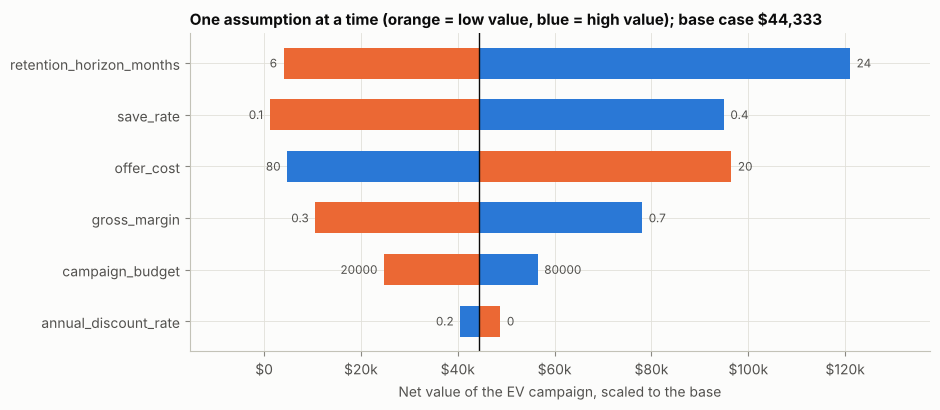

In [15]:
tornado = tg.one_way_sensitivity(test, p_test[MAIN], y_test, biz, sens["one_way"], biz["high_value_quantile"], data)
tornado_scaled = tornado.assign(**{c: tornado[c] * scale_up for c in ["net_at_low", "net_at_high", "base_net", "swing"]})
tornado_scaled.to_csv(TAB_DIR / "tornado_test_scaled_to_base.csv", index=False)
display(tornado_scaled.style.format({"net_at_low": "${:,.0f}", "net_at_high": "${:,.0f}", "base_net": "${:,.0f}",
                                     "swing": "${:,.0f}"}))

fig, ax = plt.subplots(figsize=(9.5, 4.2))
base_net = tornado_scaled["base_net"].iloc[0]
for i, r in tornado_scaled.iterrows():
    ax.barh(i, r["net_at_low"] - base_net, left=base_net, color=ORANGE, height=0.6)
    ax.barh(i, r["net_at_high"] - base_net, left=base_net, color=BLUE, height=0.6)
    ax.text(min(r["net_at_low"], r["net_at_high"]), i, f"{r['low'] if r['net_at_low'] < r['net_at_high'] else r['high']:g}  ",
            ha="right", va="center", fontsize=8.5, color=INK_2)
    ax.text(max(r["net_at_low"], r["net_at_high"]), i, f"  {r['high'] if r['net_at_low'] < r['net_at_high'] else r['low']:g}",
            ha="left", va="center", fontsize=8.5, color=INK_2)
ax.axvline(base_net, color=INK, lw=1)
ax.set_yticks(range(len(tornado_scaled)), tornado_scaled["parameter"])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(USD)
ax.set_xlabel("Net value of the EV campaign, scaled to the base")
ax.set_title(f"One assumption at a time (orange = low value, blue = high value); base case {money(base_net)}", loc="left")
xl = ax.get_xlim()
ax.set_xlim(xl[0] - (xl[1] - xl[0]) * 0.08, xl[1] + (xl[1] - xl[0]) * 0.08)
fig.tight_layout()
save(fig, "t07_tornado")

policy,Expected value (model),Highest churn risk (model)
budget_base,,
"$10,000","$16,202","$16,336"
"$20,000","$24,787","$27,137"
"$40,000","$44,333","$40,906"
"$60,000","$55,286","$51,277"
"$80,000","$56,480","$52,160"
"$120,000","$54,078","$39,475"


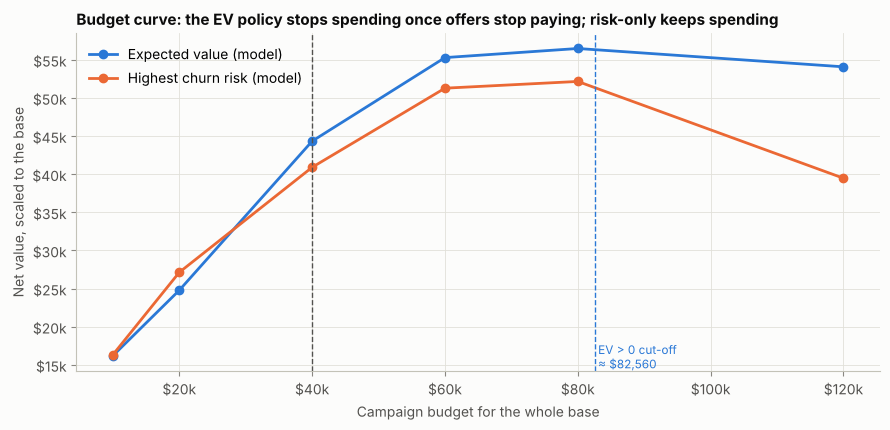

In [16]:
budgets = np.array(sens["campaign_budget"])
budget_rows = []
for b in budgets:
    bb = tg.with_params(biz, campaign_budget=float(b))
    for pol in ["ev", "risk"]:
        k = tg.n_offers(tg.split_budget(bb, len(test)), biz["offer_cost"])
        o = tg.evaluate_policy(pol, f_test, biz["save_rate"], biz["offer_cost"], k, hv_threshold)
        budget_rows.append({"budget_base": b, "policy": PL[pol], "offers_base": tg.n_offers(b, biz["offer_cost"]),
                            "contacted_test": o["contacted"], "net_test": o["net_value"],
                            "net_scaled_to_base": o["net_value"] * scale_up, "roi": o["roi"], "precision": o["precision"]})
budget_table = pd.DataFrame(budget_rows)
budget_table.to_csv(TAB_DIR / "budget_curve_test.csv", index=False)
display(budget_table.pivot(index="budget_base", columns="policy", values="net_scaled_to_base")
        .style.format("${:,.0f}").format_index("${:,.0f}"))

fig, ax = plt.subplots(figsize=(9, 4.4))
for pol in ["ev", "risk"]:
    t = budget_table[budget_table["policy"] == PL[pol]]
    ax.plot(t["budget_base"], t["net_scaled_to_base"], color=POLICY_COLORS[pol], lw=2, marker="o", label=PL[pol])
ax.axvline(biz["campaign_budget"], color=INK_2, ls="--", lw=1)
ax.axvline(rec_budget, color=BLUE, ls="--", lw=1)
ax.text(rec_budget, ax.get_ylim()[0], f" EV > 0 cut-off\n ≈ {money(rec_budget)}", color=BLUE, fontsize=8.5, va="bottom")
ax.xaxis.set_major_formatter(USD)
ax.yaxis.set_major_formatter(USD)
ax.set_xlabel("Campaign budget for the whole base")
ax.set_ylabel("Net value, scaled to the base")
ax.set_title("Budget curve: the EV policy stops spending once offers stop paying; risk-only keeps spending", loc="left")
ax.legend()
fig.tight_layout()
save(fig, "t08_budget_curve")

## 7. Target segments and segment-specific offers (test)

In [17]:
contact_test = tg.run_policy("ev", f_test, biz["save_rate"], biz["offer_cost"], k_test)
seg_test = vl.add_value_columns(test, biz, v_all).assign(
    p_churn=p_test[MAIN], risk_tier=lambda d: vl.risk_tier(d["p_churn"], biz), contact=contact_test,
    ev=tg.expected_value(p_test[MAIN], v_test, biz["save_rate"], biz["offer_cost"]),
    realized=y_test * biz["save_rate"] * v_test - biz["offer_cost"])
tiers = biz["risk_tiers"]["labels"]
matrix = seg_test.groupby(["risk_tier", "value_tier"]).agg(
    n=("y", "size"), churn_rate=("y", "mean"), mean_p=("p_churn", "mean"), mean_V=("value_proxy", "mean"),
    contacted=("contact", "sum"), mean_ev=("ev", "mean"),
).reindex(pd.MultiIndex.from_product([tiers[::-1], biz["value_tiers"]["labels"]], names=["risk_tier", "value_tier"]))
matrix["contact_rate"] = matrix["contacted"] / matrix["n"]
matrix.to_csv(TAB_DIR / "risk_value_matrix_test.csv")
display(matrix.style.format({"n": "{:,.0f}", "churn_rate": "{:.1%}", "mean_p": "{:.1%}", "mean_V": "${:,.0f}",
                             "contacted": "{:,.0f}", "mean_ev": "${:,.1f}", "contact_rate": "{:.0%}"}, na_rep="—"))

seg_test["tenure_seg"] = pd.cut(seg_test["tenure"], [-1, 12, 24, 72], labels=["0–12", "13–24", "25–72"]).astype(str)
segments = seg_test.groupby(["Contract", "InternetService", "tenure_seg"]).agg(
    n=("y", "size"), churn_rate=("y", "mean"), mean_V=("value_proxy", "mean"), contacted=("contact", "sum"),
    expected_net_if_all=("ev", "sum")).query("n >= 20")
segments["contact_rate"] = segments["contacted"] / segments["n"]
segments["share_of_offers"] = segments["contacted"] / segments["contacted"].sum()
segments = segments.sort_values("contacted", ascending=False)
segments.to_csv(TAB_DIR / "target_segments_test.csv")
display(segments.head(10).style.format({"n": "{:,}", "churn_rate": "{:.1%}", "mean_V": "${:,.0f}", "contacted": "{:,}",
                                        "expected_net_if_all": "${:,.0f}", "contact_rate": "{:.0%}",
                                        "share_of_offers": "{:.0%}"}))

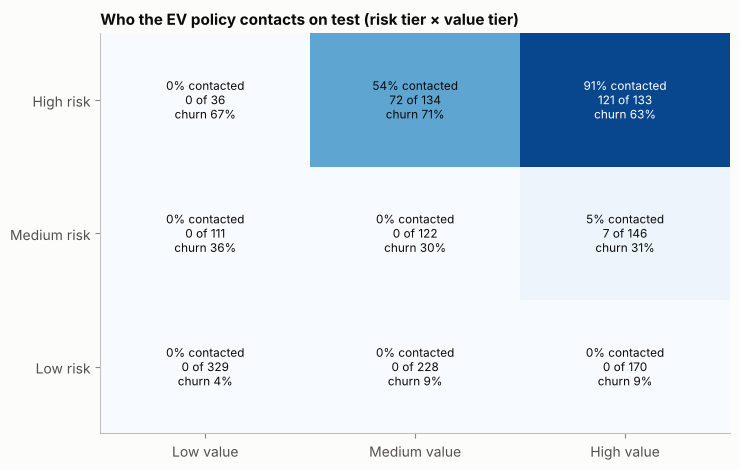

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
piv = matrix["contact_rate"].unstack().reindex(index=tiers[::-1], columns=biz["value_tiers"]["labels"])
ax.imshow(piv.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i, r in enumerate(piv.index):
    for j, c in enumerate(piv.columns):
        row = matrix.loc[(r, c)]
        ax.text(j, i, f"{row['contact_rate']:.0%} contacted\n{int(row['contacted'])} of {int(row['n'])}\n"
                      f"churn {row['churn_rate']:.0%}", ha="center", va="center", fontsize=8.5,
                color="white" if row["contact_rate"] > 0.55 else INK)
ax.set_xticks(range(3), [f"{c} value" for c in piv.columns])
ax.set_yticks(range(3), [f"{r} risk" for r in piv.index])
ax.grid(False)
ax.set_title("Who the EV policy contacts on test (risk tier × value tier)", loc="left")
fig.tight_layout()
save(fig, "t09_segment_matrix")

**Segment-specific offers (stretch, illustrative).** Instead of one offer for everyone, `config.yaml → segment_offers` gives
each segment the offer that matches its churn driver from the EDA: a contract-upgrade discount for month-to-month fiber
customers, an autopay credit for electronic-check payers, a free security/support trial for internet customers with neither
add-on. Costs and save rates are **invented for illustration**. With different costs per customer, customers are picked by
EV per dollar until the budget is spent.

In [19]:
offer_name, offer_cost_i, offer_save_i = tg.assign_offers(test, config["segment_offers"])
budget_test = tg.split_budget(biz, len(test))
seg_contact, seg_res = tg.segment_offer_campaign(p_test[MAIN], v_test, y_test, offer_cost_i, offer_save_i, budget_test)
_, seg_res_unc = tg.segment_offer_campaign(p_test[MAIN], v_test, y_test, offer_cost_i, offer_save_i, np.inf)
uni = test_policies.loc[PL["ev"]]
uni_unc = tg.evaluate_policy("ev", f_test, biz["save_rate"], biz["offer_cost"], len(test), hv_threshold)
seg_compare = pd.DataFrame({
    "One offer, reference budget": {k: uni[k] for k in ["contacted", "spend", "net_value", "precision"]},
    "Segment offers, reference budget": {k: seg_res[k] for k in ["contacted", "spend", "net_value", "precision"]},
    "One offer, no budget cap": {k: uni_unc[k] for k in ["contacted", "spend", "net_value", "precision"]},
    "Segment offers, no budget cap": {k: seg_res_unc[k] for k in ["contacted", "spend", "net_value", "precision"]},
}).T.astype(float)
seg_compare.to_csv(TAB_DIR / "segment_offers_test.csv")
display(seg_compare.style.format({"contacted": "{:,.0f}", "spend": "${:,.0f}", "net_value": "${:,.0f}",
                                  "precision": "{:.1%}"}))
offer_mix = pd.crosstab(offer_name, seg_contact, margins=True).rename(columns={False: "not contacted", True: "contacted"})
display(offer_mix)

,contacted,spend,net_value,precision
"One offer, reference budget",200,"$8,000","$8,869",68.5%
"Segment offers, reference budget",146,"$7,985","$6,284",67.1%
"One offer, no budget cap",423,"$16,920","$10,819",54.4%
"Segment offers, no budget cap",429,"$21,910","$9,965",56.4%


col_0,not contacted,contacted,All
row_0,,,
Autopay credit,109,2,111
Contract upgrade discount,293,128,421
Free security / tech-support trial,143,15,158
Generic loyalty discount,718,1,719
All,1263,146,1409


Under these illustrative numbers, segment offers do **not** automatically beat one generic offer: a cheap offer only pays if its
save rate stays high enough relative to its cost, and the contract-upgrade discount is the most expensive offer for the
largest high-risk group. What makes segment offers attractive is mostly **customer experience** (the offer fixes the reason the
customer is unhappy rather than paying them to stay) and **learning**: a small randomized pilot per offer type is the only way
to replace these invented save rates with measured ones (see the playbook).

## 8. Fairness and customer-experience checks (test)

The model does not use `gender`. It does use `SeniorCitizen`, which notebook 03 flagged. We check how offers are spread across
customer groups: contact rate, precision, and **recall among churners** (the equal-opportunity view: does a churner in group A
have the same chance of being offered help as a churner in group B?).

In [20]:
fair_rows = []
labels_map = {"SeniorCitizen": {0: "No", 1: "Yes"}, "Partner": {0: "No", 1: "Yes"}, "Dependents": {0: "No", 1: "Yes"}}
for col in ["SeniorCitizen", "gender", "Partner", "Dependents", "Contract"]:
    g = test[col].map(labels_map[col]) if col in labels_map else test[col]
    t = tg.group_table(contact_test, y_test, g)
    t.index = pd.MultiIndex.from_product([[col], t.index], names=["attribute", "group"])
    fair_rows.append(t)
fairness = pd.concat(fair_rows)
fairness.to_csv(TAB_DIR / "fairness_test.csv")
display(fairness.style.format({"n": "{:,}", "churn_rate": "{:.1%}", "contact_rate": "{:.1%}", "share_of_offers": "{:.1%}",
                               "precision": "{:.1%}", "recall_churners": "{:.1%}"}, na_rep="—"))

# Sensitivity of the fairness picture to dropping SeniorCitizen from the model: refit LR without it on train, same everything else
from sklearn.base import clone
lr_feats_ns = {**md.LR_FEATURES, "num_cols": md.LR_FEATURES["num_cols"] + ["log_TotalCharges"],
               "bin_cols": [c for c in md.LR_FEATURES["bin_cols"] if c != "SeniorCitizen"]}
pipe_ns = md.make_pipeline("lr", config, lr_feats_ns)
pipe_ns.set_params(clf__C=lr_model.pipeline.named_steps["clf"].C)
X_tr, y_tr = md.xy(train.drop(columns="split"))
pipe_ns.fit(X_tr, y_tr)
p_ns = pipe_ns.predict_proba(test.drop(columns=["split", pp.TARGET]))[:, 1]
f_ns = tg.Frame.from_df(test, p_ns, v_test, y_test)
contact_ns = tg.run_policy("ev", f_ns, biz["save_rate"], biz["offer_cost"], k_test)
ns_out = tg.outcome(contact_ns, f_ns, biz["save_rate"], biz["offer_cost"], hv_threshold)
senior_compare = pd.DataFrame({
    "with SeniorCitizen": tg.group_table(contact_test, y_test, test["SeniorCitizen"].map({0: "No", 1: "Yes"}))["recall_churners"],
    "without SeniorCitizen": tg.group_table(contact_ns, y_test, test["SeniorCitizen"].map({0: "No", 1: "Yes"}))["recall_churners"],
}).rename_axis("SeniorCitizen")
senior_compare.loc["Campaign net value"] = [test_policies.loc[PL["ev"], "net_value"], ns_out["net_value"]]
senior_compare.to_csv(TAB_DIR / "senior_citizen_ablation_test.csv")
print("Recall among churners by SeniorCitizen, and campaign net value, with and without the feature:")
display(senior_compare)

Recall among churners by SeniorCitizen, and campaign net value, with and without the feature:


,with SeniorCitizen,without SeniorCitizen
SeniorCitizen,,
No,0.344203,0.347826
Yes,0.428571,0.387755
Campaign net value,8869.088082,8498.572227


## 9. Explainability: LR scorecard and SHAP for LightGBM

**Scorecard.** The LR is written as points: +20 points doubles the odds of churning. Score = base + category points +
points × tenure + points × ln(1 + TotalCharges); p = 1 / (1 + exp(−score × ln 2 / 20)). The check below rebuilds every test
customer's probability from the table alone.

In [21]:
card = sc.scorecard_table(lr_model, pdo=20)
card.to_csv(TAB_DIR / "churn_scorecard.csv", index=False)
_, p_card = sc.score_customers(lr_model, test)
print(f"Max |p from scorecard − p from model| on test: {np.abs(p_card - p_test['lr']).max():.2e}")
display(card.style.format({"points": "{:+.1f}", "coef": "{:+.3f}", "odds_ratio": "{:.2f}"}, na_rep=""))

Max |p from scorecard − p from model| on test: 2.78e-16


,feature,level,points,coef,odds_ratio
0,Base points,"reference customer, all numeric inputs = 0",+61.0,,
1,tenure,per month,-0.2,-0.006,0.99
2,log_TotalCharges,per unit of ln(1 + TotalCharges),-14.4,-0.499,0.61
3,Contract,Month-to-month (reference),+0.0,+0.000,1.00
4,Contract,One year,-22.2,-0.770,0.46
5,Contract,Two year,-52.5,-1.821,0.16
6,InternetService,DSL (reference),+0.0,+0.000,1.00
7,InternetService,Fiber optic,+29.3,+1.016,2.76
8,InternetService,No,-33.3,-1.154,0.32
9,PaymentMethod,Bank transfer (automatic) (reference),+0.0,+0.000,1.00


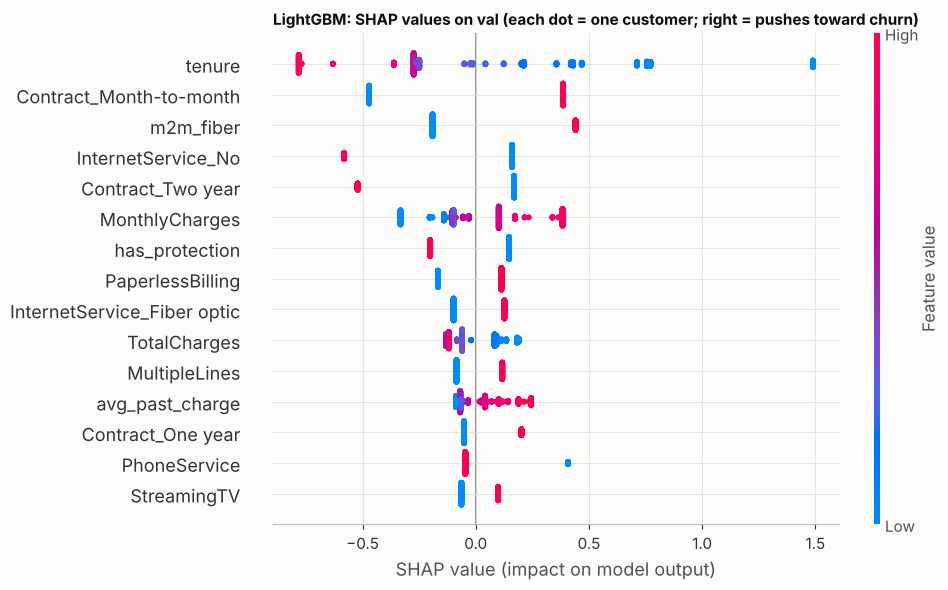

,LightGBM (mean |SHAP|),LR (mean |contribution|)
1,tenure,InternetService
2,Contract_Month-to-month,Contract
3,m2m_fiber,log_TotalCharges
4,InternetService_No,MultipleLines
5,Contract_Two year,PaymentMethod
6,MonthlyCharges,StreamingTV
7,has_protection,StreamingMovies
8,PaperlessBilling,PaperlessBilling
9,InternetService_Fiber optic,OnlineSecurity
10,TotalCharges,tenure


In [22]:
import warnings
warnings.filterwarnings("ignore")   # tqdm / SHAP output-format notices
import shap

lgbm_pipe = models["lgbm"].pipeline
X_val_t = lgbm_pipe[:-1].transform(val.drop(columns=["split", pp.TARGET]))
explainer = shap.TreeExplainer(lgbm_pipe.named_steps["clf"])
shap_values = explainer.shap_values(X_val_t)
shap_values = shap_values[1] if isinstance(shap_values, list) else shap_values
shap_imp = pd.Series(np.abs(shap_values).mean(axis=0), index=X_val_t.columns, name="mean |SHAP| (log-odds)") \
    .sort_values(ascending=False)
shap_imp.to_csv(TAB_DIR / "shap_lgbm_val.csv")

fig = plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_val_t, max_display=15, show=False, plot_size=None, color_bar_label="Feature value")
plt.gca().set_title("LightGBM: SHAP values on val (each dot = one customer; right = pushes toward churn)", loc="left")
plt.tight_layout()
save(plt.gcf(), "t10_shap_lgbm")

lr_rank = sc.contributions(lr_model, val, train.drop(columns="split")).abs().mean().sort_values(ascending=False)
display(pd.DataFrame({"LightGBM (mean |SHAP|)": shap_imp.head(10).index,
                      "LR (mean |contribution|)": lr_rank.head(10).index}, index=range(1, 11)))

Both models agree on the main drivers: contract type, tenure / lifetime charges, fiber internet, electronic-check payment and
missing security/support add-ons. LightGBM chose stumps (no interactions, notebook 03), so its SHAP values are additive like
the LR contributions. This agreement is why the simpler LR loses nothing as the main model.

## 10. Customer-level targeting table

Every customer in the base is scored with the main model and ranked by EV. `contact = True` marks the campaign the reference
budget buys for the whole base (top EV customers with EV > 0). Notes:
- Train customers' probabilities are in-sample (the model was fit on them). LR is small and regularised, so the gap is small
  (train vs test log loss below), but the `split` column is kept so it is visible.
- In real use the table would be produced for **active** customers at the start of the month; here it covers the snapshot.
- The actual churn label is **not** in the table: it is unknown at decision time.

In [23]:
p_all = {m: models[m].predict_churn(data) for m in md.MODELS}
ll = {s: md.log_loss(data.loc[data["split"] == s, pp.TARGET], p_all[MAIN][data["split"] == s]) for s in ["train", "val", "test"]}
print("LR log loss by split:", {k: round(v, 4) for k, v in ll.items()})

table = vl.add_value_columns(data, biz, v_all)
table["p_churn"] = p_all[MAIN]
table["risk_tier"] = vl.risk_tier(table["p_churn"], biz)
table["expected_value"] = tg.expected_value(table["p_churn"], table["value_proxy"], biz["save_rate"], biz["offer_cost"])
table["breakeven_p"] = tg.breakeven_p(table["value_proxy"], biz["save_rate"], biz["offer_cost"])
table["priority_rank"] = table["expected_value"].rank(ascending=False, method="first").astype(int)
k_base = tg.n_offers(biz["campaign_budget"], biz["offer_cost"])
table["contact"] = (table["priority_rank"] <= k_base) & (table["expected_value"] > 0)
table["worth_contacting_if_budget_allows"] = table["expected_value"] > 0
table["segment"] = table["risk_tier"] + " risk / " + table["value_tier"] + " value"
table["suggested_offer"] = tg.assign_offers(data, config["segment_offers"])[0]
contrib_all = sc.contributions(lr_model, data, train.drop(columns="split"))
table["top_reasons"] = sc.top_reasons(contrib_all, data)
table["scorecard_points"] = np.round(sc.score_customers(lr_model, data)[0], 1)

TABLE_COLS = ["priority_rank", "customerID", "split", "contact", "worth_contacting_if_budget_allows", "p_churn", "risk_tier",
              "value_proxy", "value_tier", "past_value", "segment", "expected_value", "breakeven_p", "scorecard_points",
              "top_reasons", "suggested_offer", "Contract", "InternetService", "PaymentMethod", "tenure", "MonthlyCharges",
              "SeniorCitizen"]
targeting_table = table[TABLE_COLS].sort_values("priority_rank").reset_index(drop=True)
targeting_table.to_csv(TAB_DIR / "customer_targeting_table.csv", index=False)

scores = data[[pp.ID_COL, "split", pp.TARGET]].assign(**{f"p_{m}": p_all[m] for m in md.MODELS})
scores.to_csv(TAB_DIR / "customer_scores.csv", index=False)   # includes y: for evaluation and the dashboard, not for targeting
print(f"Reference campaign for the base: {targeting_table['contact'].sum():,} customers "
      f"(EV > 0 overall: {targeting_table['worth_contacting_if_budget_allows'].sum():,})")
display(targeting_table.head(10).style.format({"p_churn": "{:.1%}", "value_proxy": "${:,.0f}", "past_value": "${:,.0f}",
                                              "expected_value": "${:,.0f}", "breakeven_p": "{:.1%}",
                                              "MonthlyCharges": "${:,.2f}"}))

LR log loss by split: {'train': 0.4016, 'val': 0.4216, 'test': 0.4125}


Reference campaign for the base: 1,000 customers (EV > 0 overall: 2,055)


,priority_rank,customerID,split,contact,worth_contacting_if_budget_allows,p_churn,risk_tier,value_proxy,value_tier,past_value,segment,expected_value,breakeven_p,scorecard_points,top_reasons,suggested_offer,Contract,InternetService,PaymentMethod,tenure,MonthlyCharges,SeniorCitizen
0,1,7216-EWTRS,train,True,True,93.5%,High,$575,High,$101,High risk / High value,$94,27.8%,76.700000,low lifetime charges ($101); internet: Fiber optic; contract: Month-to-month,Contract upgrade discount,Month-to-month,Fiber optic,Electronic check,1,$100.80,1
1,2,5419-JPRRN,train,True,True,92.3%,High,$578,High,$101,High risk / High value,$93,27.7%,71.500000,low lifetime charges ($101); internet: Fiber optic; contract: Month-to-month,Contract upgrade discount,Month-to-month,Fiber optic,Electronic check,1,$101.45,0
2,3,1400-MMYXY,test,True,True,87.2%,High,$604,High,$335,High risk / High value,$92,26.5%,55.500000,internet: Fiber optic; contract: Month-to-month; low lifetime charges ($335),Contract upgrade discount,Month-to-month,Fiber optic,Electronic check,3,$105.90,1
3,4,6496-SLWHQ,train,True,True,87.8%,High,$599,High,$294,High risk / High value,$91,26.7%,57.000000,internet: Fiber optic; low lifetime charges ($294); contract: Month-to-month,Contract upgrade discount,Month-to-month,Fiber optic,Electronic check,3,$105.00,1
4,5,0107-YHINA,val,True,True,90.5%,High,$569,High,$100,High risk / High value,$89,28.1%,64.900000,low lifetime charges ($100); internet: Fiber optic; contract: Month-to-month,Contract upgrade discount,Month-to-month,Fiber optic,Electronic check,1,$99.75,0
5,6,7181-BQYBV,test,True,True,87.8%,High,$584,High,$102,High risk / High value,$88,27.4%,56.800000,low lifetime charges ($102); internet: Fiber optic; contract: Month-to-month,Contract upgrade discount,Month-to-month,Fiber optic,Electronic check,1,$102.45,0
6,7,1875-QIVME,val,True,True,85.7%,High,$595,High,$243,High risk / High value,$87,26.9%,51.600000,internet: Fiber optic; low lifetime charges ($243); contract: Month-to-month,Contract upgrade discount,Month-to-month,Fiber optic,Electronic check,2,$104.40,0
7,8,5178-LMXOP,test,True,True,93.1%,High,$542,High,$95,High risk / High value,$86,29.5%,74.900000,low lifetime charges ($95); internet: Fiber optic; contract: Month-to-month,Contract upgrade discount,Month-to-month,Fiber optic,Electronic check,1,$95.10,1
8,9,3178-FESZO,train,True,True,87.9%,High,$571,High,$100,High risk / High value,$86,28.0%,57.100000,low lifetime charges ($100); internet: Fiber optic; contract: Month-to-month,Contract upgrade discount,Month-to-month,Fiber optic,Credit card (automatic),1,$100.25,0
9,10,0295-PPHDO,test,True,True,91.8%,High,$544,High,$95,High risk / High value,$85,29.4%,69.700000,low lifetime charges ($95); internet: Fiber optic; contract: Month-to-month,Contract upgrade discount,Month-to-month,Fiber optic,Electronic check,1,$95.45,0


In [24]:
with pd.ExcelWriter(OUT_DIR / "targeting_report.xlsx", engine="openpyxl") as xw:
    assumptions.to_excel(xw, sheet_name="Assumptions")
    targeting_table.to_excel(xw, sheet_name="Targeting table", index=False)
    card.to_excel(xw, sheet_name="Churn scorecard", index=False)
    test_metrics.to_excel(xw, sheet_name="Model metrics (test)")
    test_policies[cols].astype(float).to_excel(xw, sheet_name="Policies (test)")
    grid.to_excel(xw, sheet_name="Sensitivity (test)", index=False)
    tornado_scaled.to_excel(xw, sheet_name="Tornado (base)", index=False)
    segments.to_excel(xw, sheet_name="Target segments (test)")
    fairness.to_excel(xw, sheet_name="Fairness (test)")
print("Saved", (OUT_DIR / "targeting_report.xlsx").relative_to(ROOT))

Saved targeting_output/targeting_report.xlsx


In [25]:
ev_row, risk_row = test_policies.loc[PL["ev"]], test_policies.loc[PL["risk"]]
summary = {
    "assumptions": {k: biz[k] for k in ["gross_margin", "retention_horizon_months", "annual_discount_rate", "offer_cost",
                                        "save_rate", "campaign_budget"]},
    "main_model": MAIN,
    "test": {
        "n": len(test), "offers": k_test,
        "roc_auc": test_metrics.loc[LABELS[MAIN], "roc_auc"], "pr_auc": test_metrics.loc[LABELS[MAIN], "pr_auc"],
        "ece": test_metrics.loc[LABELS[MAIN], "ece"], "brier": test_metrics.loc[LABELS[MAIN], "brier"],
        **{f"{pol}_{m}": float(test_policies.loc[PL[pol], m]) for pol in ["ev", "risk", "value", "eda_rule", "random", "oracle"]
           for m in ["net_value", "precision", "recall", "hv_churner_coverage", "roi"]},
        "ev_net_lo": float(ev_row["net_value_lo"]), "ev_net_hi": float(ev_row["net_value_hi"]),
        "ev_minus_risk": float(ev_row["net_diff_vs_ref"]), "ev_minus_risk_lo": float(ev_row["net_diff_lo"]),
        "ev_minus_risk_hi": float(ev_row["net_diff_hi"]), "p_ev_better_than_risk": float(ev_row["p_better_than_ref"]),
    },
    "scaled_to_base": {
        "factor": scale_up, "offers": k_base, "ev_net": float(ev_row["net_value"]) * scale_up,
        "ev_net_lo": float(ev_row["net_value_lo"]) * scale_up, "ev_net_hi": float(ev_row["net_value_hi"]) * scale_up,
        "risk_net": float(risk_row["net_value"]) * scale_up, "spend": biz["campaign_budget"],
        "tornado": {r["parameter"]: [r["net_at_low"], r["net_at_high"]] for _, r in tornado_scaled.iterrows()},
        "grid_min": float(grid["ev_net"].min() * scale_up), "grid_max": float(grid["ev_net"].max() * scale_up),
    },
    "campaign_size": {"ev_positive_share_val": k_opt_share, "recommended_offers_base": rec_offers,
                      "recommended_budget_base": rec_budget,
                      "net_test_at_recommended": float(curves_test["ev"][k_rec_test]) * scale_up,
                      "ev_positive_base": int(targeting_table["worth_contacting_if_budget_allows"].sum())},
    "grid": {"cells_not_paying": int(len(breakeven_cells)), "cells": len(grid),
             "ev_beats_risk_share": float((grid["ev_minus_risk"] >= 0).mean())},
}
with open(TAB_DIR / "summary.json", "w") as fh:
    json.dump(summary, fh, indent=2, default=float)
print(json.dumps(summary, indent=2, default=lambda x: round(float(x), 4)))

{
  "assumptions": {
    "gross_margin": 0.5,
    "retention_horizon_months": 12,
    "annual_discount_rate": 0.1,
    "offer_cost": 40,
    "save_rate": 0.25,
    "campaign_budget": 40000
  },
  "main_model": "lr",
  "test": {
    "n": 1409,
    "offers": 200,
    "roc_auc": 0.8479397556123899,
    "pr_auc": 0.6663781101168005,
    "ece": 0.022420019520991052,
    "brier": 0.13464288995594492,
    "ev_net_value": 8869.088081913818,
    "ev_precision": 0.685,
    "ev_recall": 0.3663101604278075,
    "ev_hv_churner_coverage": 0.5339805825242718,
    "ev_roi": 1.1086360102392272,
    "risk_net_value": 8183.491245077446,
    "risk_precision": 0.725,
    "risk_recall": 0.3877005347593583,
    "risk_hv_churner_coverage": 0.34951456310679613,
    "risk_roi": 1.0229364056346808,
    "value_net_value": 604.9457074809379,
    "value_precision": 0.29,
    "value_recall": 0.15508021390374332,
    "value_hv_churner_coverage": 0.5631067961165048,
    "value_roi": 0.07561821343511724,
    "eda_rule_

## 11. Summary

All money figures assume the base case in `config.yaml` (offer $40, save rate 25%, margin 50%, 12-month horizon) and are
**expected values under those assumptions**, not measured campaign results. Test numbers are for 1,409 customers;
"base" figures multiply by 7,043 / 1,409 ≈ 5.

**Model.** Logistic regression is the main model: tied with RF and LightGBM on every metric and on campaign value (val), easier
to explain, and exactly expressible as a points scorecard. Test: ROC-AUC 0.848, PR-AUC 0.666, ECE 0.022, i.e. the
probabilities are reliable enough to plug into the EV formula.

**Targeting at the reference budget ($40k → 1,000 offers for the base, 200 on test).**

| Policy (test, 200 offers) | Net value | ≈ Whole base | Precision | High-value churners reached |
|---|---|---|---|---|
| **Expected value (model)** | **$8,869** [7,049 – 10,492] | **≈ $44k** | 68.5% | **53%** |
| Highest churn risk (model) | $8,183 | ≈ $41k | 72.5% | 35% |
| EDA rule (M2M + Fiber, newest first) | $7,707 | ≈ $39k | 67.0% | 30% |
| Highest value only | $605 | ≈ $3k | 29.0% | 56% |
| Random | −$2,495 | ≈ −$12k | 26.5% | 14% |

- EV earns about **$780 more than risk-only on test** (+9.6%), but the 95% CI of the difference is [−$262, +$1,942]: EV is
  ahead in 92% of bootstrap samples, which is suggestive, not conclusive, at this budget. Its clear gain is **reaching 53% of
  high-value churners instead of 35%**, by trading a little precision for value.
- Both model-based policies beat the model-free EDA rule and are far ahead of value-only and random targeting.

**Campaign size.** On val, 29% of customers have EV > 0, i.e. about **2,060 offers (≈ $83k)** for the base. On test that
cut-off earns $11,045 (≈ $55k for the base) versus $8,869 at the reference budget. If the budget can grow to around $80k it
pays; beyond the EV > 0 cut-off every extra offer loses money (profit curve, t05). EV's advantage over risk-only grows with the
budget because EV knows where to stop: at $120k it earns ≈ $54k versus ≈ $39k for risk-only (t08). At small budgets
($10–20k) the two are equivalent.

**Sensitivity.** The result depends mainly on the assumptions that cannot be measured from this data:
retention horizon (6 → 24 months: ≈ $4k → $121k for the base), save rate (10% → 40%: ≈ $1k → $95k) and offer cost
($20 → $80: ≈ $96k → $5k). In 15 of the 64 save-rate × offer-cost scenarios the campaign does not pay at all
(save rate 5% with offers ≥ $30, 10% with ≥ $60, 15% with ≥ $80, 20–25% with $150 offers); the EV policy then contacts no
one instead of losing money.
**The ranking of customers does not depend on any of these assumptions**; only the cut-off and the payoff do.

**Who gets offers.** 199 of the 200 test offers go to month-to-month fiber customers, two thirds of them in their first year.
High-risk but low-value customers get none (EV < 0). Senior citizens are contacted more (29% vs 11%) because they churn more
(44% vs 23%); dropping `SeniorCitizen` from the model narrows the recall gap (43%/34% → 39%/35%) at a cost of about 4% of
campaign value. `gender` is not used and its recall is balanced (36% vs 38%).

**Limitations.** No randomized campaign (save rate and offer cost are assumptions; no uplift or causal claim); fictional sample
data from one snapshot (no temporal validation, uncertain external validity); value proxy ignores cross-sell, acquisition cost
and price changes; test set of 1,409 customers gives wide CIs. The next step in a real telco is a randomized pilot (treatment
vs hold-out within the EV-selected list) to measure the save rate per offer type.